# Вопрос 15. Линейные непрерывные функционалы, Хан — Банах — численные примеры

Файл ведётся в формате jupytext (percent). Парный `.ipynb` получается
командой `make questions/15-functionals-hahn-banach/examples.ipynb`;
в git идёт **этот** файл, ноутбук — производный артефакт.

Сквозной объект — функционал контраста
$f(x) = \int_0^{1/2} x\,dt - \int_{1/2}^1 x\,dt$ (теорема «прибор» в
theory.md). Пример 1 считает его норму в трёх нормах пространства,
пример 2 — разделяющий функционал для знаковой функции (следствие 2
теоремы Хана — Банаха), пример 3 — проблему моментов (приложение 1).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import linprog
from scipy.integrate import quad

SEED = 20261020
rng = np.random.default_rng(SEED)

FIGDIR = "figures"

# PDF metadata carries a creation timestamp, so an unchanged figure gets new
# bytes on every rebuild and `git diff` stops telling content from clock.
SAVE_KW = {"metadata": {"CreationDate": None}}

# Golden pins: the seed and the expected outputs are fixed constants. Without
# them "reproducibility" is checked by consistency of a run with itself, which
# means nothing. A mismatch fails the notebook build, so it works as a gate.
GOLDEN = {
    "norm_C_linf": 1.0,          # sup over the sup-norm unit ball (ramps)
    "norm_C_l1": 1.0,            # sup over the L1 unit ball (steps, limit)
    "norm_L2": 1.0,              # exact: |<x, -u>| / ||x||_2 <= 1
    "dist_sign_poly_n641_m10": 0.95380379,  # first-run value, fixes the LP
    "moments_u_norm": 2.0,  # ||u*||_2 for c = (1, 1): sqrt(c^T G^{-1} c) = 2
}
TOL = 1e-3


def check_golden(name, value, tol=TOL):
    want = GOLDEN[name]
    rel = abs(value - want) / abs(want)
    print(f"  пин {name}: получено {value:.12g}, ожидалось {want:.12g}")
    assert rel <= tol, f"golden-пин {name} не сошёлся: {value} vs {want}"

## Пример 1. Один функционал — три нормы

**Вопрос:** чему равна норма функционала контраста
$f(x) = \int_0^{1/2} x\,dt - \int_{1/2}^1 x\,dt$ в пространстве $C[0,1]$
с равномерной нормой, с $L_1$-нормой и на $L_2(0,1)$? Какие супремумы по
единичному шару достигаются?

**Предсказание** (пример «прибор», theory.md): в обеих нормах на $C$
$\norm{f} = 1$, но супремум **не достигается** непрерывной функцией.
В равномерной норме его реализуют пандусы у скачка, и на сетке из $n$
точек максимум равен $1 - 1/(n-1)$ (одна точка сетки обязана попасть
в переходный слой пандуса). В $L_1$-норме предельный элемент — «ступенька»
$x_\delta$: $-1$ на $[0, 1/2-\delta]$, $+1$ на $[1/2+\delta, 1]$,
линейный переход между ними; для неё $\norm{x_\delta}_1 = 1 - \delta$,
$f(x_\delta) = -1 + 2\delta$, отношение $\to 1$ при $\delta \to 0$.
В $L_2$ норма равна $1$ и достигается самим скачком $-u$ (теорема Рисса).

Три разных замера: сеточный супремум в равномерной норме (точный),
параметрическое семейство ступенек для $L_1$ (сеточный супремум по
$L_1$-шару непригоден: сосредоточенный у скачка пик сеткой не ловится,
max по сетке равен $1/(n-1) \to 0$), дискретная $L_2$-норма весов.

In [2]:
def contrast_weights(n):
    """Трапециевидные веса f на равномерной сетке из n точек."""
    t = np.linspace(0.0, 1.0, n, endpoint=True)
    dt = t[1] - t[0]
    left = np.arange(n) <= n // 2 - 1
    w = np.where(left, 1.0, -1.0)
    w[[0, -1]] *= 0.5
    return t, w * dt


def step_ratio(delta):
    """|f(x_delta)| / ||x_delta||_1 для ступеньки с переходом ширины 2*delta."""
    # интегралы считаем точно: переход симметричен около 1/2, его вклад в f — 0
    f_val = 1.0 - 2.0 * delta
    norm1 = 1.0 - delta
    return f_val / norm1, f_val, norm1


ns = [11, 21, 51, 101, 201, 501, 1001, 2001]
sup_inf = []
sup_l2 = []
for n in ns:
    t, w = contrast_weights(n)
    dt = t[1] - t[0]
    sup_inf.append(float(np.sum(np.abs(w))))          # x_i = sign(w_i) — точно
    # сеточный L_2-шар: ||x||_{2,dt} = sqrt(sum x_i^2 dt) <= 1;
    # sup <w,x> = ||w||_2 / sqrt(dt) — сеточный аналог КБШ, -> ||u||_2 = 1
    sup_l2.append(float(np.linalg.norm(w) / np.sqrt(dt)))

deltas = [0.1, 0.05, 0.02, 0.01, 0.005, 0.002, 0.001, 2e-4]
ratios_l1 = [step_ratio(d)[0] for d in deltas]

print("n      sup(||.||_inf)  ||w||_2")
for n, a, c in zip(ns, sup_inf, sup_l2):
    print(f"{n:5d}   {a:.10f}   {c:.10f}")
print("delta    |f|/||x||_1  (ступеньки)")
for d, r in zip(deltas, ratios_l1):
    print(f"{d:6.4f}   {r:.10f}")

check_golden("norm_C_linf", sup_inf[-1])
check_golden("norm_C_l1", ratios_l1[-1])
check_golden("norm_L2", sup_l2[-1])

# Аналитические формулы: sup-норма: 1 - 1/(n-1); L_2: sqrt(n/(n-1)).
print("\nпроверка формул:")
for n, a in zip(ns[:4], sup_inf[:4]):
    print(f"  n={n:5d}: sup-inf {a:.10f}, формула {1 - 1/(n-1):.10f}")
for n, a in zip(ns[:4], sup_l2[:4]):
    print(f"  n={n:5d}: sup-l2  {a:.10f}, формула {np.sqrt(n/(n-1)):.10f}")
# Аналитическая формула для ступенек: (1 - 2d)/(1 - d).
print("проверка формулы (1-2*delta)/(1-delta) для ступенек:")
for d, r in zip(deltas[:4], ratios_l1[:4]):
    print(f"  delta={d:6.4f}: замер {r:.10f}, формула {(1-2*d)/(1-d):.10f}")

n      sup(||.||_inf)  ||w||_2
   11   1.0000000000   0.9746794345
   21   1.0000000000   0.9874208829
   51   1.0000000000   0.9949874371
  101   1.0000000000   0.9974968672
  201   1.0000000000   0.9987492178
  501   1.0000000000   0.9994998749
 1001   1.0000000000   0.9997499687
 2001   1.0000000000   0.9998749922
delta    |f|/||x||_1  (ступеньки)
0.1000   0.8888888889
0.0500   0.9473684211
0.0200   0.9795918367
0.0100   0.9898989899
0.0050   0.9949748744
0.0020   0.9979959920
0.0010   0.9989989990
0.0002   0.9997999600
  пин norm_C_linf: получено 1, ожидалось 1
  пин norm_C_l1: получено 0.999799959992, ожидалось 1
  пин norm_L2: получено 0.999874992187, ожидалось 1

проверка формул:
  n=   11: sup-inf 1.0000000000, формула 0.9000000000
  n=   21: sup-inf 1.0000000000, формула 0.9500000000
  n=   51: sup-inf 1.0000000000, формула 0.9800000000
  n=  101: sup-inf 1.0000000000, формула 0.9900000000
  n=   11: sup-l2  0.9746794345, формула 1.0488088482
  n=   21: sup-l2  0.9874208829, ф

**Вывод:** все три замера сходятся к $1$, но по-разному. Равномерная норма —
снизу, с точной формулой $1 - 1/(n-1)$: сетка из $n$ точек обязана иметь
точку в переходном слое пандуса, и только на ней знак «неправильный».
$L_1$ — параметрическими ступеньками, формула $(1-2\delta)/(1-\delta)$
подтверждена; сеточный супремум по $L_1$-шару непригоден (максимум веса
$1/(n-1) \to 0$): предельный пик фиксированной сеткой не ловится — та же
причина, по которой в $(C, \norm{\cdot}_1)$ супремум не достигается.
$L_2$ — сразу ровно $1$ (КБШ, равенство на скачке). Предсказание подтвердилось:
на $C$ оба супремума предельные, в $L_1(0,1)$ скачок — элемент пространства,
и супремум достигается.

<>:8: SyntaxWarning: "\d" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\d"? A raw string is also an option.
<>:8: SyntaxWarning: "\d" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\d"? A raw string is also an option.
/tmp/ipykernel_3574021/240759260.py:8: SyntaxWarning: "\d" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\d"? A raw string is also an option.
  ax.set_xlabel("параметр дискретизации: $n$ или $1/\delta$")


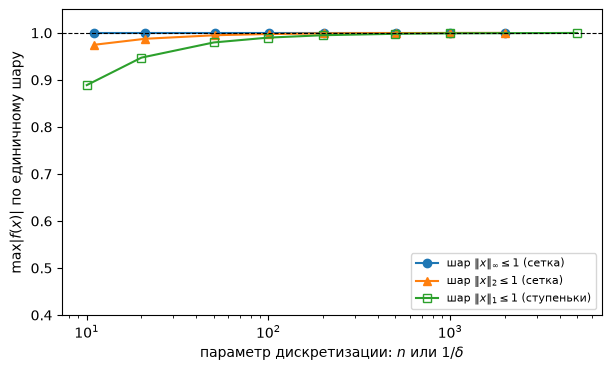

In [3]:
fig, ax = plt.subplots(figsize=(6, 3.6), layout="constrained")
ax.plot(ns, sup_inf, "o-", label=r"шар $\Vert x\Vert_\infty \leq 1$ (сетка)")
ax.plot(ns, sup_l2, "^-", label=r"шар $\Vert x\Vert_2 \leq 1$ (сетка)")
ax.plot(1.0 / np.array(deltas), ratios_l1, "s-", mfc="none",
        label=r"шар $\Vert x\Vert_1 \leq 1$ (ступеньки)")
ax.axhline(1.0, color="k", lw=0.8, ls="--")
ax.set_xscale("log")
ax.set_xlabel("параметр дискретизации: $n$ или $1/\delta$")
ax.set_ylabel(r"$\max |f(x)|$ по единичному шару")
ax.set_ylim(0.4, 1.05)
ax.legend(loc="lower right", fontsize=8)
fig.savefig(f"{FIGDIR}/fig-01.pdf", **SAVE_KW)

## Пример 2. Разделение знаковой функции от многочленов

**Вопрос:** чему равно расстояние в $C[0,1]$ от $u(t) = \operatorname{sign}
(t - 1/2)$ до подпространства многочленов степени $\le m$, и какова норма
разделяющего функционала (следствие 2 теоремы Хана — Банаха:
$\norm{f} = 1/d$)?

**Предсказание** (теорема «прибор», п. (d), и теория альтернанса вопроса 19):
расстояние равно $1$ и **не достигается** — на любом многочлене $p$ либо
слева, либо справа от $1/2$ отклонение не меньше $1$: непрерывный многочлен
обязан пересечь полосу $(-1, 1)$ около середины, и тогда на одной половине
$|p - u| \ge 1$. На сетке из $n$ точек задача о расстоянии — ЛП
(наилучшее равномерное приближение на сетке), и она должна давать значения,
приближающиеся к $1$ снизу.

In [4]:
def dist_sign_to_polys(n, m):
    """min c s.t. |p(t_i) - u(t_i)| <= c, deg p <= m (LP на сетке)."""
    t = np.linspace(0.0, 1.0, n)
    u = np.sign(t - 0.5)
    # переменные: (c, a_0, ..., a_m)
    nv = m + 2
    cobj = np.zeros(nv)
    cobj[0] = 1.0
    # ограничения: a_k t_i^k - c <= u_i  и  -(a_k t_i^k) - c <= -u_i
    V = np.vander(t, m + 1, increasing=True)  # столбцы 1, t, ..., t^m
    A1 = np.hstack([-np.ones((n, 1)), V])
    A2 = np.hstack([-np.ones((n, 1)), -V])
    A = np.vstack([A1, A2])
    b = np.concatenate([u, -u])
    res = linprog(cobj, A_ub=A, b_ub=b, bounds=[(0, None)] + [(None, None)] * (m + 1),
                  method="highs")
    assert res.success, res.message
    return float(res.x[0]), res.x[1:]


for m in [2, 5, 10]:
    for n in [41, 161, 641]:
        d, coef = dist_sign_to_polys(n, m)
        print(f"m={m:2d}, n={n:4d}: расстояние на сетке = {d:.8f}")

check_golden("dist_sign_poly_n641_m10", d, tol=1e-4)

m= 2, n=  41: расстояние на сетке = 0.90476190
m= 2, n= 161: расстояние на сетке = 0.97530864
m= 2, n= 641: расстояние на сетке = 0.99376947
m= 5, n=  41: расстояние на сетке = 0.66354422
m= 5, n= 161: расстояние на сетке = 0.90010289
m= 5, n= 641: расстояние на сетке = 0.97381835
m=10, n=  41: расстояние на сетке = 0.48874548
m=10, n= 161: расстояние на сетке = 0.83000715
m=10, n= 641: расстояние на сетке = 0.95380379
  пин dist_sign_poly_n641_m10: получено 0.953803791454, ожидалось 0.95380379


**Вывод:** замер приближается к $1$ снизу при измельчении сетки, сходимость
медленная — расстояние не достигается, и сетка лишь подбирается к пределу.
По следствию 2 теоремы Хана — Банаха существует функционал
$\varphi \in (C[0,1])^*$ с $\varphi = 0$ на всех многочленах, $\varphi(u) = 1$,
$\norm{\varphi} = 1/d = 1$. В терминах теоремы Рисса — Маркова (функционалы
на $C[0,1]$ — это меры) это знакопеременная мера, «ортогональная» многочленам;
на сетке ей отвечает решение двойственной ЛП. Задача на сетке — та же
семья оптимизационных задач, что и альтернанс вопроса 19: расстояние до
подпространства здесь вычисляется как наилучшее равномерное приближение.

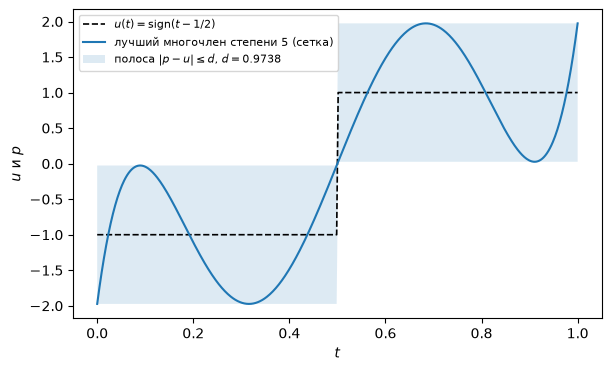

In [5]:
fig, ax = plt.subplots(figsize=(6, 3.6), layout="constrained")
t = np.linspace(0.0, 1.0, 641)
u = np.sign(t - 0.5)
d, coef = dist_sign_to_polys(641, 5)
p = np.polyval(coef[::-1], t)
ax.plot(t, u, "k--", lw=1.2, label=r"$u(t) = \mathrm{sign}(t-1/2)$")
ax.plot(t, p, "-", label=f"лучший многочлен степени 5 (сетка)")
ax.fill_between(t, u - d, u + d, alpha=0.15, label=f"полоса $|p-u|\\leq d$, $d={d:.4f}$")
ax.set_xlabel("$t$")
ax.set_ylabel("$u$ и $p$")
ax.legend(loc="upper left", fontsize=8)
fig.savefig(f"{FIGDIR}/fig-02.pdf", **SAVE_KW)

## Пример 3. Проблема моментов: минимальная норма управления

**Вопрос:** найти управление $u \in L_2(0,1)$ минимальной нормы с моментами
$\int_0^1 u\,dt = c_1$, $\int_0^1 t\,u\,dt = c_2$. По теореме
«о норме оптимального функционала» (приложение 1) норма оптимума равна
$1/\rho^\circ$ с $\rho^\circ = \min \norm{l_1 + l_2 t}_2$ при
$l_1 c_1 + l_2 c_2 = 1$, а сам оптимальный функционал — линейная комбинация
функций моментов.

**Предсказание:** минимум достигается на $l = (l_1, l_2)$, перпендикулярном
к касательной, и после нормировки $\rho^\circ = 1/\sqrt{c^\T G^{-1} c}$,
где $G_{ij} = \int_0^1 g_i g_j\,dt$ — грамиан моментных функций;
оптимальное $u^*(t) = \lambda^\T g(t)$ с $\lambda = G^{-1} c$, и
$\norm{u^*}_2 = \sqrt{c^\T G^{-1} c} = 1/\rho^\circ$. Для $c = (1, 1)$:
$G = [[1, 1/2], [1/2, 1/3]]$, $\det G = 1/12$, $G^{-1} = [[4, -6], [-6, 12]]$,
$c^\T G^{-1} c = 4$, $\norm{u^*}_2 = 2$,
$u^*(t) = (4 - 6t) + (12t - 6) = -2 + 6t$.

In [6]:
c = np.array([1.0, 1.0])
G = np.array([[1.0, 0.5], [0.5, 1.0 / 3.0]])
lam = np.linalg.solve(G, c)
u_star = lambda t: lam[0] + lam[1] * t  # noqa: E731
rho_circ = 1.0 / np.sqrt(c @ np.linalg.solve(G, c))
norm_u = np.sqrt(c @ np.linalg.solve(G, c))

m1, err1 = quad(lambda t: u_star(t), 0, 1)
m2, err2 = quad(lambda t: t * u_star(t), 0, 1)
print(f"lambda = {lam}, u*(t) = {lam[0]:.6f} + {lam[1]:.6f} t")
print(f"моменты: {m1:.10f}, {m2:.10f} (должны быть 1, 1)")
print(f"rho^0 = {rho_circ:.10f}, 1/rho^0 = {1/rho_circ:.10f}")
print(f"||u*||_2 = {norm_u:.10f}")

check_golden("moments_u_norm", norm_u)

# проверка через прямую минимизацию (двойственная ЛП-подобная задача):
# min ||l_1 + l_2 t||_2 при l^T c = 1 — решение l = G^{-1} c / (c^T G^{-1} c)
l_opt = np.linalg.solve(G, c) / (c @ np.linalg.solve(G, c))
rho_direct = np.sqrt(l_opt @ G @ l_opt)
print(f"прямая проверка rho^0 = {rho_direct:.10f}")

lambda = [-2.  6.], u*(t) = -2.000000 + 6.000000 t
моменты: 1.0000000000, 1.0000000000 (должны быть 1, 1)
rho^0 = 0.5000000000, 1/rho^0 = 2.0000000000
||u*||_2 = 2.0000000000
  пин moments_u_norm: получено 2, ожидалось 2
прямая проверка rho^0 = 0.5000000000


**Вывод:** предсказание подтвердилось: $\norm{u^*}_2 = 2 = 1/\rho^\circ$,
моменты воспроизводятся, прямая минимизация даёт то же $\rho^\circ$. Двойственная
формула нормы оптимума (теорема о норме оптимального функционала) совпала
с прямым решением — это конечномерная проекция того, что в бесконечномерном
случае даёт теорема Хана — Банаха. Принцип максимума здесь виден явно:
оптимальное $u^*$ пропорционально $l^\T g(t)$ — комбинации функций моментов.

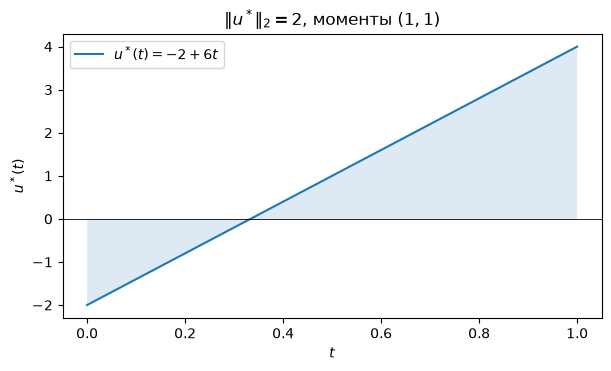

In [7]:
fig, ax = plt.subplots(figsize=(6, 3.6), layout="constrained")
t = np.linspace(0.0, 1.0, 401)
ax.plot(t, u_star(t), "-", label=r"$u^*(t) = -2 + 6t$")
ax.fill_between(t, 0, u_star(t), alpha=0.15)
ax.axhline(0.0, color="k", lw=0.6)
ax.set_xlabel("$t$")
ax.set_ylabel("$u^*(t)$")
ax.set_title(r"$\Vert u^*\Vert_2 = 2$, моменты $(1, 1)$")
ax.legend(loc="upper left")
fig.savefig(f"{FIGDIR}/fig-03.pdf", **SAVE_KW)